# Métricas en la red de exportaciones de vehiculos

## 0. Instalación y librerías

In [275]:
import numpy as np
import pandas as pd
import country_converter as coco

import networkx as nx
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import ipywidgets as widgets
import scipy
import math
import seaborn as sns
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from pathlib import Path
from itertools import combinations

sns.set_theme("notebook",'darkgrid')
sns.color_palette("magma", as_cmap=True)

SEMILLA = 42                     
plt.rcParams["figure.dpi"] = 110

for nombre, modulo in [("networkx", nx), ("pandas", pd), ("numpy", np), ("scipy", scipy), ("ipywidgets", widgets)]:
    print(f"{nombre:11s}", modulo.__version__)

root = next(
    (p for p in Path('__file__').resolve().parents if (p / ".git").exists()),
    Path('__file__').resolve().parent, 
)

networkx    3.7
pandas      3.1.1
numpy       2.5.5
scipy       1.18.1
ipywidgets  8.1.9


## 1. Los datos

Los datos fueron extraidos de UN COMTRADE, a partir de una API que nos permite descargar por pais las exportaciones que reportan para distintos productos y distintos destinos. La informacion tene una granularidad mensual que fue agregada en pasos previos. 

- **Nodos:** Paises
- **Aristas:** hay un vínculo direccionado entre un pais A y un pais B si A exporta vehiculos a B.
- **Peso (`weight`):** Monto en USD exportado.

Se trata de una red dirigida, pesada, y dinamica

## 2. Redes y grafos

In [276]:
G = nx.MultiDiGraph()  # Use nx.MultiGraph() if undirected
YEARS = range(2018,2025)

for year in YEARS:
    path = root / 'data' / f'hs8703_{year}.graphml.xml'
    snapshot = nx.read_graphml(path)

    for node, node_attr in snapshot.nodes(data=True):
        G.add_node(node, **node_attr )

    for idx, (u, v, edge_attrs) in enumerate(snapshot.edges(data=True)):
        new_key = f'{year}_{idx}'
        G.add_edge(u,v,key=new_key,year=year, **edge_attrs)

In [277]:
def get_year_graph(G, target_year):
    matching_edges = [
        (u, v, k)
        for u, v, k, data in G.edges(keys=True, data=True)
        if data.get("year") == target_year
    ]
    return G.edge_subgraph(matching_edges)

data = {}
for year in YEARS:
    sG = get_year_graph(G, year)
    nodes = sG.number_of_nodes()
    edges = sG.number_of_edges()
    total_export_millions = sum(data['weight'] for u,v,data in sG.edges(data=True))/1_000_000
    data[year] = {'nodes':nodes,'edges':edges,'total_export_millions':total_export_millions}

pd.DataFrame(data)


,2018,2019,2020,2021,2022,2023,2024
nodes,231.000000,231.000000,226.000000,229.000000,230.000000,231.000000,229.000000
edges,6628.000000,6572.000000,6003.000000,6257.000000,6343.000000,6164.000000,5826.000000
total_export_millions,749418.812326,737060.176597,614068.049003,693874.631638,761785.529432,931688.135259,925389.603524


Analizamos ver que valor minimo determinamos para el peso de los ejes. Con 10M de piso para las aristas, conservamos mas del 99% del valor con solo el 25% de las aristas

In [278]:
for year in YEARS:
    edges_data = [e['weight'] for _,_, e in G.edges(data=True) if e['year'] == year]
    edges_above_5m= [
                        e['weight'] for _,_, e in G.edges(data=True) 
                        if e['weight'] > 10_000_000 and e['year'] == year
                        ]
    
    print(f"Year: {year}===================")
    print(f'Valor retenido: {sum(edges_above_5m) / sum(edges_data) * 100:.2f}%')
    print(f'Aristas retenidas: {len(edges_above_5m) / len(edges_data)*100:.2f}% - {len(edges_above_5m)}')


Year: 2018===================
Valor retenido: 99.24%
Aristas retenidas: 25.56% - 1694
Year: 2019===================
Valor retenido: 99.21%
Aristas retenidas: 25.75% - 1692
Year: 2020===================
Valor retenido: 99.12%
Aristas retenidas: 24.95% - 1498
Year: 2021===================
Valor retenido: 99.22%
Aristas retenidas: 26.45% - 1655
Year: 2022===================
Valor retenido: 99.25%
Aristas retenidas: 27.81% - 1764
Year: 2023===================
Valor retenido: 99.42%
Aristas retenidas: 29.30% - 1806
Year: 2024===================
Valor retenido: 99.43%
Aristas retenidas: 29.95% - 1745


### 2.2 Tres formas de representar la misma red

Tomamos data para un par de paises

In [279]:
AMERICAS = [
    "ARG",  # Argentina
    "BOL",  # Bolivia
    "BRA",  # Brazil
    "CHL",  # Chile
    "COL",  # Colombia
    "ECU",  # Ecuador
    "MEX",  # Mexico
    "PAN",  # Panama
    "PER",  # Peru
    "PRY",  # Paraguay
    "USA",  # USA
    "VEN",   # Venezuela
    "CAN"   # CANADA
]

aristas = combinations(AMERICAS, 2)

In [320]:
S = G.subgraph(AMERICAS)

#print("Lista de aristas (con peso):")
# for u, v, d in S.edges(data=True):
#     print(f"  {u} — {v}  Exportaciones en USD {d['weight']} - año {d['year']}")

print("\nLista de adyacencia:")
for v in S.nodes():
    print(f"  {v}: {list(S.neighbors(v))}")


Lista de adyacencia:
  USA: ['CAN', 'BOL', 'PER', 'ARG', 'PAN', 'COL', 'MEX', 'ECU', 'BRA', 'PRY', 'VEN', 'CHL']
  CAN: ['USA', 'BOL', 'PER', 'ARG', 'PAN', 'COL', 'MEX', 'ECU', 'BRA', 'PRY', 'VEN', 'CHL']
  BOL: ['USA', 'CAN', 'PER', 'ARG', 'COL', 'ECU', 'BRA', 'PRY', 'VEN', 'CHL']
  PER: ['USA', 'CAN', 'BOL', 'ARG', 'PAN', 'COL', 'MEX', 'ECU', 'BRA', 'PRY', 'VEN', 'CHL']
  ARG: ['BRA', 'CHL', 'COL', 'ECU', 'PAN', 'PER', 'PRY', 'USA']
  PAN: ['VEN']
  COL: ['USA', 'CAN', 'BOL', 'PER', 'ARG', 'PAN', 'MEX', 'ECU', 'BRA', 'VEN', 'CHL']
  MEX: ['USA', 'CAN', 'BOL', 'PER', 'ARG', 'PAN', 'COL', 'ECU', 'BRA', 'PRY', 'VEN', 'CHL']
  ECU: ['COL', 'USA', 'PAN', 'PER', 'CAN', 'VEN']
  BRA: ['USA', 'CAN', 'BOL', 'PER', 'ARG', 'PAN', 'COL', 'MEX', 'ECU', 'PRY', 'VEN', 'CHL']
  PRY: ['ARG', 'BOL', 'BRA', 'USA', 'CAN', 'CHL', 'PER']
  VEN: []
  CHL: ['USA', 'CAN', 'BOL', 'PER', 'ARG', 'PAN', 'COL', 'MEX', 'ECU', 'BRA', 'PRY', 'VEN']


Matriz de adyacencia (sin pesos):


,ARG,BOL,BRA,CHL,COL,ECU,MEX,PAN,PER,PRY,USA,VEN,CAN
ARG,0,0,7,2,1,1,0,1,1,1,3,0,0
BOL,2,0,3,2,2,5,0,0,6,4,7,1,1
BRA,7,7,0,7,7,7,7,7,7,7,7,6,7
CHL,7,7,5,0,3,7,2,5,7,7,7,6,4
COL,7,6,7,6,0,7,7,7,7,0,7,4,7
ECU,0,0,0,0,5,0,0,1,3,0,5,1,1
MEX,7,7,7,7,7,7,0,7,7,7,7,7,7
PAN,0,0,0,0,0,0,0,0,0,0,0,1,0
PER,3,3,3,3,3,4,2,3,0,2,4,1,3
PRY,1,1,7,3,0,0,0,0,1,0,7,0,1


C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
C:\Users\liher\AppData\Local\Temp\ipykernel_12664\3019210776.py:13: RuntimeWarning: divide by zero encountered in l

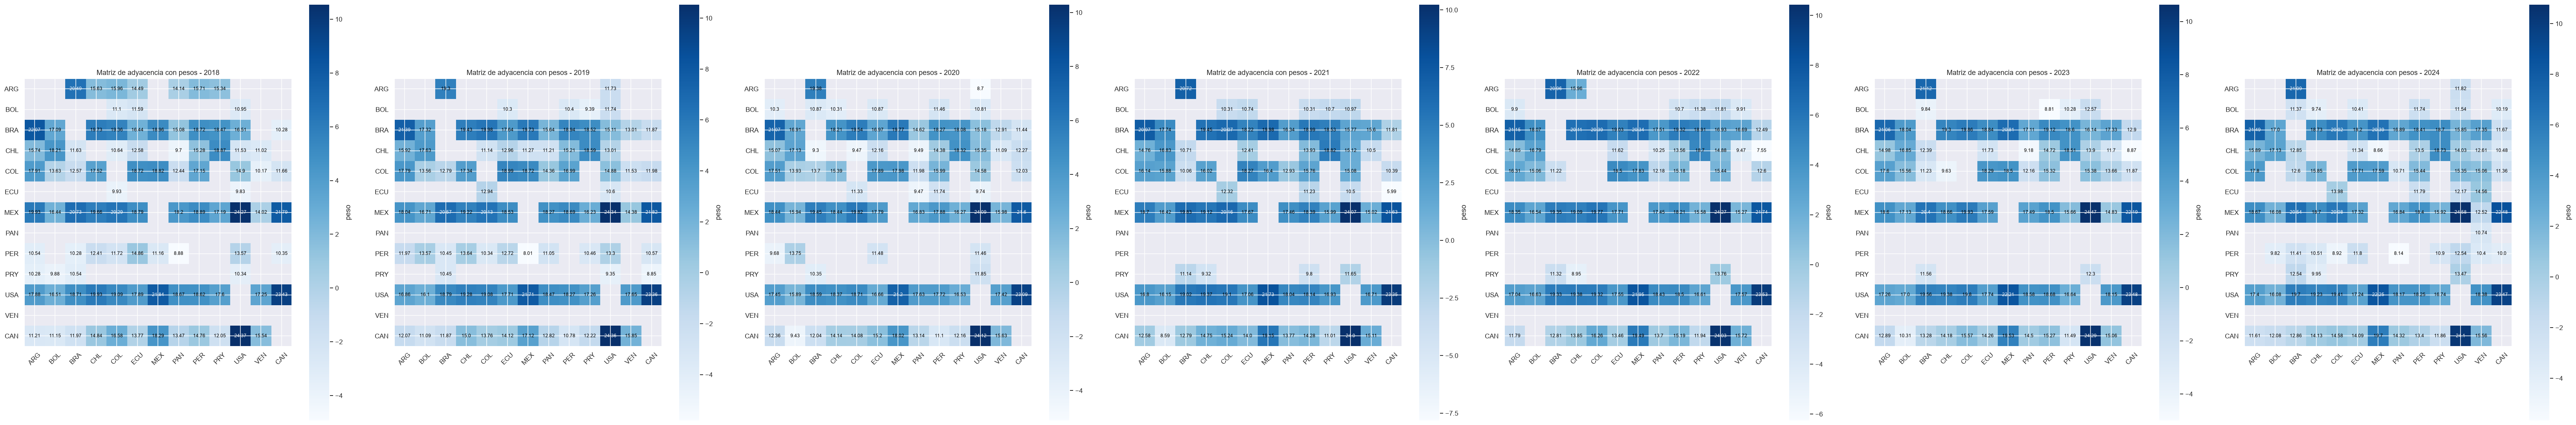

In [289]:
A = nx.to_pandas_adjacency(S, nodelist=AMERICAS, weight=None, dtype=int)     # 1 si hay arista, 0 si no
W = nx.to_pandas_adjacency(S, nodelist=AMERICAS, weight="weight", dtype=int) # con pesos

print("Matriz de adyacencia (sin pesos):")
display(A)

redes = [get_year_graph(G,year) for year in YEARS]

fig, axes = plt.subplots(figsize=(60,10), ncols=len(redes))

for red, ax, year in zip(redes, axes.flatten(), YEARS):
  W = nx.to_pandas_adjacency(red, nodelist=AMERICAS, weight="weight", dtype=int) # con pesos
  im = ax.imshow(np.log(W.values/1_000_000), cmap="Blues")
  ax.set_xticks(range(len(AMERICAS)), [n.split("-")[0] for n in AMERICAS], rotation=45)
  ax.set_yticks(range(len(AMERICAS)), [n.split("-")[0] for n in AMERICAS])
  for i in range(len(AMERICAS)):
      for j in range(len(AMERICAS)):
          if W.values[i, j] > 0:
                ax.text(j, i, round(np.log(W.values[i, j]),2), ha="center", va="center", fontsize=8,
                      color="white" if round(np.log(W.values[i, j]),2) > 20 else "black")
  ax.set_title(f"Matriz de adyacencia con pesos - {year}")
  plt.colorbar(im, ax=ax, label="peso")

plt.tight_layout()
plt.show()

Grados desde la matriz: {'ARG': 17, 'BOL': 33, 'BRA': 83, 'CHL': 67, 'COL': 72, 'ECU': 16, 'MEX': 84, 'PAN': 1, 'PER': 34, 'PRY': 21, 'USA': 84, 'VEN': 0, 'CAN': 83}

Red completa: 43793 aristas de 189196 posibles. Densidad = 0.810
En los grafos multidireccionales la densidad puede ser mayor a 1 porque se permiten aristas paralelas.
Podemos calcular la densidad promedio de los anios o calcular la densidad convirtiendolo en un DiGaph
Densidad promedio 0.11920
Mayor promedio 0.12475
Menor promedio 0.11158


,2018,2019,2020,2021,2022,2023,2024
nodes,231.000000,231.000000,226.000000,229.000000,230.000000,231.000000,229.000000
edges,6628.000000,6572.000000,6003.000000,6257.000000,6343.000000,6164.000000,5826.000000
total_export_millions,749418.812326,737060.176597,614068.049003,693874.631638,761785.529432,931688.135259,925389.603524
densidad,0.124751,0.123697,0.118053,0.119838,0.120429,0.116017,0.111584


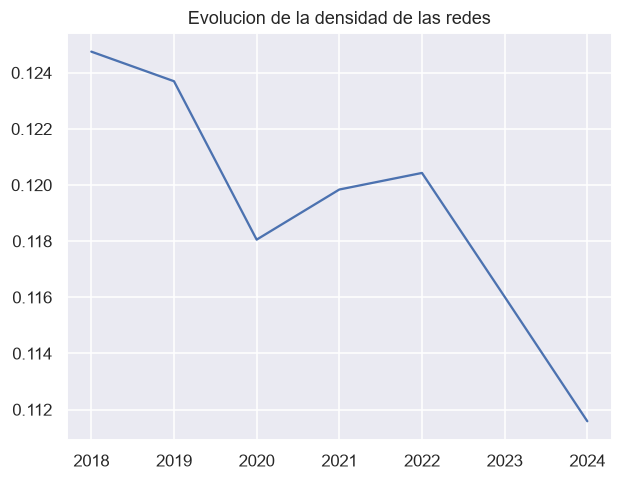

In [282]:
print("Grados desde la matriz:", A.sum(axis=1).to_dict())
N, L = G.number_of_nodes(), G.number_of_edges()
print(f"\nRed completa: {L} aristas de {N*(N-1)//2*7} posibles. Densidad = {nx.density(G):.3f}")
print("En los grafos multidireccionales la densidad puede ser mayor a 1 porque se permiten aristas paralelas.\nPodemos calcular la densidad promedio de los anios o calcular la densidad convirtiendolo en un DiGaph")

densidades = [nx.density(get_year_graph(G, year)) for year in YEARS]
print(f'Densidad promedio {np.mean(densidades):.5f}')
print(f'Mayor promedio {np.max(densidades):.5f}')
print(f'Menor promedio {np.min(densidades):.5f}')
sns.lineplot(x=YEARS, y=densidades)
plt.title("Evolucion de la densidad de las redes")

for year in YEARS:
    data[year]['densidad'] = nx.density(get_year_graph(G, year))

pd.DataFrame(data)

### 2.3 Grafos dirigidos (un ejemplo de juguete)

Nuestra red es no dirigida. Si en lugar de co-apariciones registráramos *quién le habla a quién*, sería **dirigida**: cada nodo tendría grado de entrada y de salida, y la distancia de A a B podría ser distinta de la de B a A.

Grado de entrada: {'AGO': 237, 'ARE': 504, 'ARG': 225, 'ATG': 127, 'BEL': 544, 'BRA': 245, 'CIV': 264, 'CMR': 330, 'COD': 257, 'COG': 239, 'CPV': 133, 'CUB': 126, 'ECU': 222, 'FRA': 494, 'GBR': 519, 'GHA': 323, 'GIN': 241, 'LBN': 306, 'MLI': 191, 'MRT': 214, 'NAM': 137, 'NGA': 379, 'PRT': 351, 'SEN': 299, 'STP': 80, 'TGO': 236, 'USA': 653, 'ZAF': 356, 'ZMB': 206, 'ZWE': 183, 'AND': 133, 'AUT': 327, 'CHE': 391, 'CHN': 444, 'DEU': 572, 'DZA': 232, 'ESP': 443, 'GUY': 146, 'HKG': 271, 'ITA': 429, 'LTU': 292, 'LUX': 234, 'MDG': 198, 'POL': 363, 'ROU': 335, 'SWE': 313, 'ABW': 123, 'AFG': 153, 'AIA': 48, 'ALB': 257, 'ARM': 198, 'AUS': 354, 'AZE': 233, 'BDI': 140, 'BEN': 241, 'BFA': 208, 'BGD': 154, 'BGR': 303, 'BHR': 217, 'BIH': 236, 'BLR': 227, 'BOL': 173, 'CAF': 110, 'CAN': 414, 'CHL': 262, 'COL': 221, 'COM': 80, 'CRI': 225, 'CUW': 158, 'CYM': 135, 'CYP': 252, 'CZE': 326, 'DJI': 201, 'DMA': 111, 'DNK': 305, 'DOM': 210, 'EGY': 338, 'ERI': 34, 'EST': 252, 'ETH': 209, 'FIN': 269, 'FJI': 104, '

<Axes: >

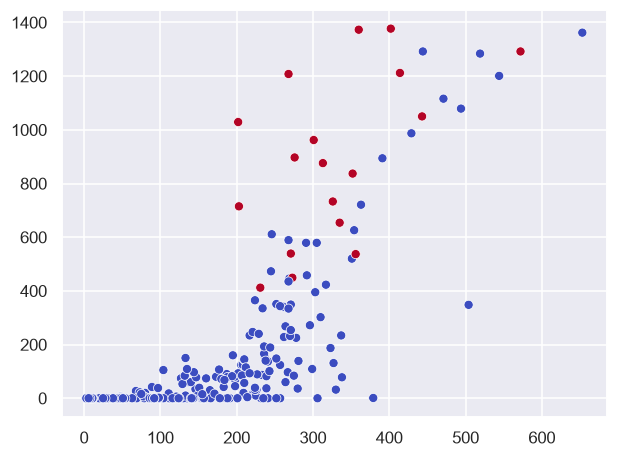

In [283]:
print("Grado de entrada:", dict(G.in_degree()))
print("Grado de salida: ", dict(G.out_degree()))
print("¿Fuertemente conexa?", nx.is_strongly_connected(G), "   ¿Débilmente conexa?", nx.is_weakly_connected(G))
print("Componentes fuertemente conexas:", [sorted(c) for c in nx.strongly_connected_components(G)])
print("Distancia A → E:", nx.shortest_path_length(G, "ARG", "SGP"), "   ¿Hay camino de E a A?", nx.has_path(G, "ARG", "SGP"))

net_exporters = []

for node in G.nodes:
    out_weight = G.out_degree(node, weight="weight")
    in_weight = G.in_degree(node, weight="weight")

    if out_weight > in_weight:
        net_exporters.append(node)

sns.scatterplot(
    x=dict(G.in_degree()), 
    y=dict(G.out_degree()),
    c=[node in net_exporters for node in G.nodes],
    cmap='coolwarm',
    )


## 3. Distribución de grados

El **grado** $k_i$ de un personaje es cuántos personajes distintos aparecen cerca de él. La **fuerza** $s_i = \sum_j w_{ij}$ es la suma de los pesos de sus aristas: cuántas co-apariciones tiene en total.

Una verificación rápida: en una red no dirigida $\sum_i k_i = 2L$, porque cada arista suma 1 al grado de sus dos extremos. Por eso $\langle k \rangle = 2L/N$.

In [314]:
for year, red in zip(YEARS,redes):
    out_d = sum([d for _, d in red.out_degree])
    N = len(red.nodes)
    in_d = sum([d for _, d in red.in_degree])
    data[year]['average_directed_degree'] = out_d / N
    data[year]['max_out_degree'] = max(red.out_degree, key=lambda x:x[1])
    data[year]['max_in_degree'] = max(red.in_degree, key=lambda x:x[1])


pd.DataFrame(data)

,2018,2019,2020,2021,2022,2023,2024
nodes,231,231,226,229,230,231,229
edges,6628,6572,6003,6257,6343,6164,5826
total_export_millions,749418.812326,737060.176597,614068.049003,693874.631638,761785.529432,931688.135259,925389.603524
densidad,0.124751,0.123697,0.118053,0.119838,0.120429,0.116017,0.111584
max_out_degree,"(JPN, 199)","(JPN, 201)","(USA, 198)","(KOR, 197)","(KOR, 197)","(KOR, 197)","(JPN, 196)"
max_in_degree,"(USA, 99)","(USA, 97)","(USA, 96)","(USA, 89)","(USA, 92)","(USA, 96)","(USA, 84)"
average_directed_degree,28.692641,28.450216,26.561947,27.323144,27.578261,26.683983,25.441048


In [334]:
def tabla_top(G, n=10):
    df = pd.DataFrame({"Pais": G.nodes(),
                       "grado_salida": [G.out_degree(v) for v in G.nodes()],
                       "grado_entrada": [G.in_degree(v) for v in G.nodes()],
                       "fuerza": [G.out_degree(v, weight="weight") for v in G.nodes()]})
    return df.sort_values("grado_salida", ascending=False).head(n).reset_index(drop=True)

for year, red in zip(YEARS,redes):
    print(f"Year {year}=================")
    display(tabla_top(red))

Year 2018=================


,Pais,grado_salida,grado_entrada,fuerza
0,JPN,199,56,9.721391e+10
1,KOR,196,56,3.818017e+10
2,USA,195,99,5.094208e+10
3,DEU,187,94,1.534341e+11
4,GBR,186,80,4.193243e+10
5,BEL,183,84,2.189779e+10
6,CHN,181,68,8.626623e+09
7,THA,176,44,1.121551e+10
8,CAN,172,59,4.095558e+10
9,ARE,170,72,8.662218e+09


Year 2019=================


,Pais,grado_salida,grado_entrada,fuerza
0,JPN,201,62,9.584500e+10
1,USA,199,97,5.549920e+10
2,KOR,199,56,4.035082e+10
3,GBR,192,81,3.842106e+10
4,DEU,187,89,1.424986e+11
5,BEL,182,80,2.442236e+10
6,CHN,182,69,8.630429e+09
7,ARE,178,63,7.737631e+09
8,CAN,174,58,4.062393e+10
9,NLD,170,76,6.789213e+09


Year 2020=================


,Pais,grado_salida,grado_entrada,fuerza
0,USA,198,96,4.484419e+10
1,JPN,196,62,7.892210e+10
2,KOR,192,50,3.549906e+10
3,DEU,186,79,1.217518e+11
4,GBR,184,73,2.618584e+10
5,CHN,182,51,9.925917e+09
6,CAN,179,51,3.206001e+10
7,THA,167,33,8.404618e+09
8,BEL,165,78,2.210102e+10
9,NLD,162,65,5.412281e+09


... (4 outputs left out)

Year 2023=================


,Pais,grado_salida,grado_entrada,fuerza
0,KOR,197,47,6.775120e+10
1,JPN,195,56,1.078562e+11
2,USA,193,96,6.248362e+10
3,CHN,188,67,7.728596e+10
4,DEU,184,77,1.768662e+11
5,GBR,179,76,3.671753e+10
6,THA,177,39,1.276702e+10
7,CAN,166,62,3.770403e+10
8,BEL,160,74,2.803639e+10
9,NLD,153,63,6.664525e+09


Year 2024=================


,Pais,grado_salida,grado_entrada,fuerza
0,JPN,196,48,1.045153e+11
1,KOR,195,47,6.782332e+10
2,CHN,190,58,8.959192e+10
3,USA,189,84,5.838602e+10
4,GBR,184,60,3.564471e+10
5,DEU,178,72,1.740872e+11
6,THA,174,32,1.217274e+10
7,CAN,172,60,3.179702e+10
8,BEL,169,66,2.605621e+10
9,FRA,150,63,2.260716e+10


In [344]:
def pk(G):
    k = np.array([d for _, d in G.degree()])
    valores, cuentas = np.unique(k, return_counts=True)
    return valores, cuentas / len(k)

def ccdf(G, type='all'):
    match type:
        case 'in':
            k = np.array([d for _, d in G.in_degree()])
        case 'out' :
            k = np.array([d for _, d in G.out_degree()])
        case 'all':
            k = np.array([d for _, d in G.degree()])

    valores = np.unique(k)
    return valores, np.array([(k >= v).mean() for v in valores])




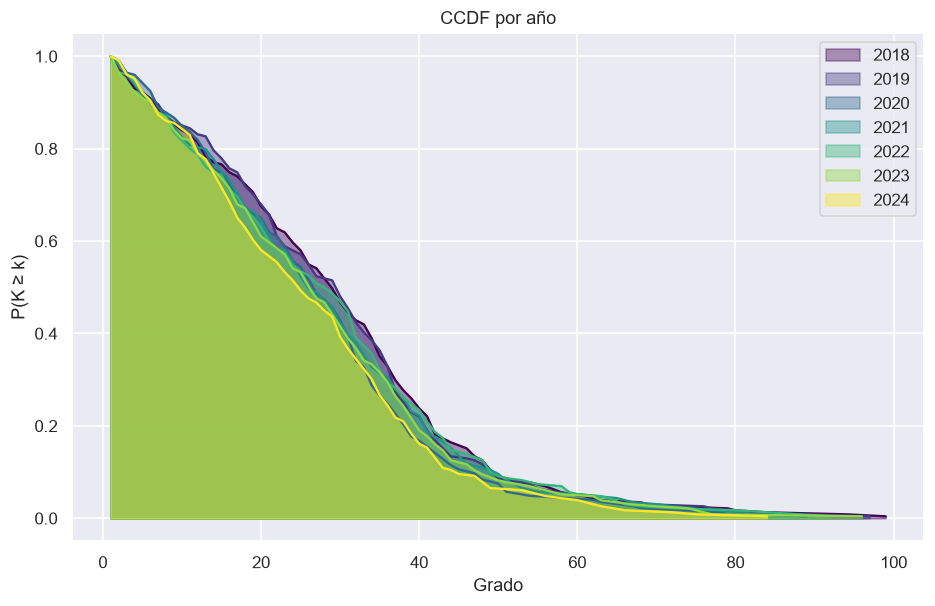

In [345]:
fig, ax = plt.subplots(figsize=(10, 6))

cmap = plt.cm.viridis(np.linspace(0, 1, len(redes)))

for red, ano, color in zip(redes, YEARS, cmap):
    x, y = ccdf(red,type='in')

    ax.fill_between(
        x, y,
        alpha=0.4,
        color=color,
        label=str(ano)
    )

    ax.plot(x, y, color=color)

ax.set_title("CCDF por año")
ax.set_xlabel("Grado")
ax.set_ylabel("P(K ≥ k)")
ax.legend()
plt.show()

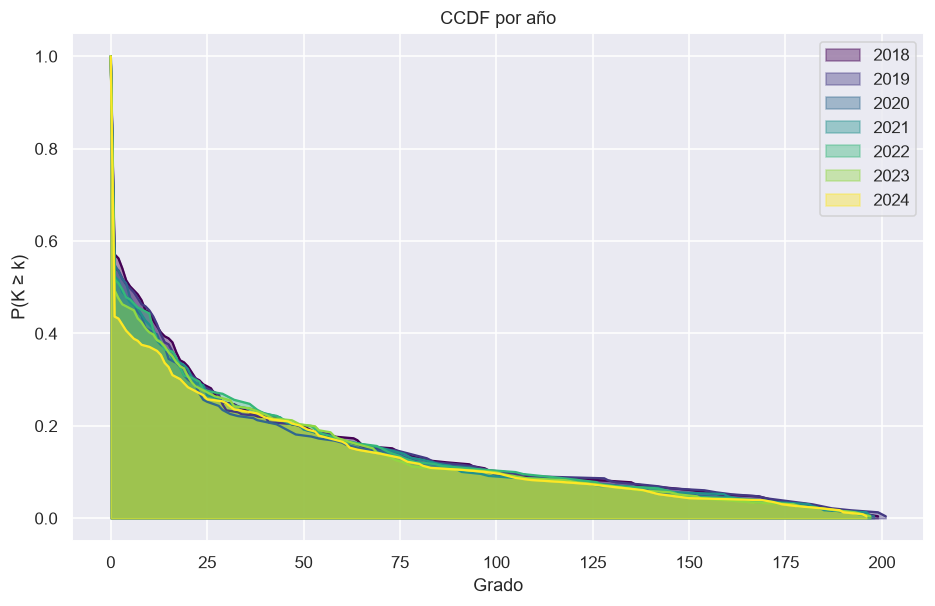

In [346]:
fig, ax = plt.subplots(figsize=(10, 6))

cmap = plt.cm.viridis(np.linspace(0, 1, len(redes)))

for red, ano, color in zip(redes, YEARS, cmap):
    x, y = ccdf(red,type='out')

    ax.fill_between(
        x, y,
        alpha=0.4,
        color=color,
        label=str(ano)
    )

    ax.plot(x, y, color=color)

ax.set_title("CCDF por año")
ax.set_xlabel("Grado")
ax.set_ylabel("P(K ≥ k)")
ax.legend()
plt.show()

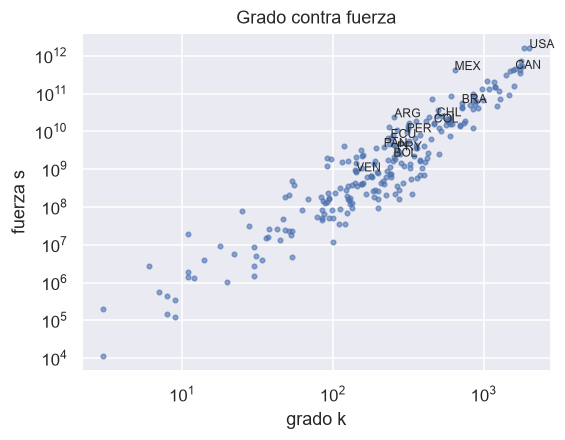

In [350]:
k = np.array([G.degree(v) for v in G.nodes()])
s = np.array([G.degree(v, weight="weight") for v in G.nodes()])

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(k, s, "o", ms=3, alpha=0.6)
for v in AMERICAS:
    ax.annotate(v, (G.degree(v), G.degree(v, weight="weight")), fontsize=8)
ax.set(xlabel="grado k", ylabel="fuerza s", title="Grado contra fuerza")
plt.show()

## 4. Visualizaciones

Para dibujar una red hay que decidir dónde va cada nodo: eso lo hace un **layout**. No hay un dibujo "correcto"; cada layout destaca cosas distintas. Probemos cuatro:

- **spring** (Fruchterman–Reingold): las aristas son resortes y los nodos se repelen. Los grupos muy conectados quedan juntos.
- **Kamada–Kawai**: busca que la distancia en el dibujo sea proporcional a la distancia en la red.
- **circular**: todos los nodos en un círculo. No usa la estructura para ubicarlos.
- **espectral**: usa autovectores del laplaciano de la red como coordenadas.

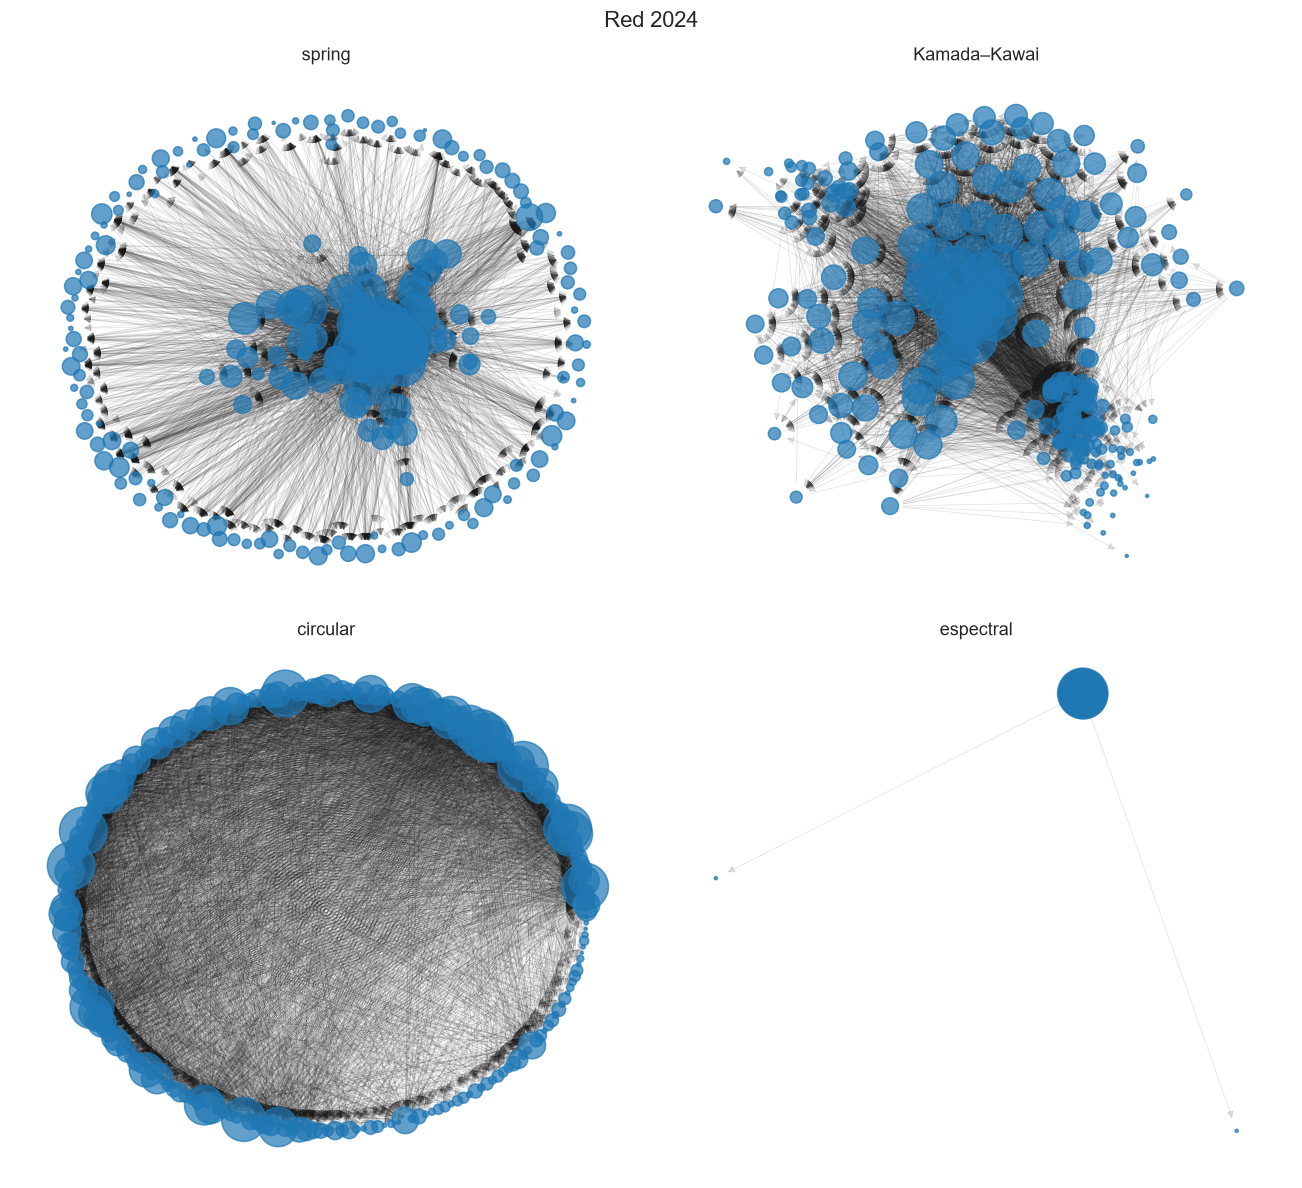

In [354]:
def calcular_layouts(G):
    return {"spring": nx.spring_layout(G, k=0.35, iterations=100, seed=SEMILLA),
            "Kamada–Kawai": nx.kamada_kawai_layout(G, weight=None),
            "circular": nx.circular_layout(G),
            "espectral": nx.spectral_layout(G, weight=None)}

layouts = calcular_layouts(red)

def dibujar_layouts(G, layouts, titulo, camino=None, n_etiquetas=6):
    grados = dict(G.degree())
    top = sorted(grados, key=grados.get, reverse=True)[:n_etiquetas]
    fig, axs = plt.subplots(2, 2, figsize=(12, 11))
    for ax, (nombre_layout, pos) in zip(axs.flat, layouts.items()):
        nx.draw_networkx_edges(G, pos, alpha=0.12, width=0.5, ax=ax)
        nx.draw_networkx_nodes(G, pos, node_size=[4 * grados[v] for v in G], node_color="tab:blue", alpha=0.7, ax=ax)
        etiquetas = {v for v in (camino if camino else top)}
        if camino:
            aristas_camino = list(zip(camino[:-1], camino[1:]))
            nx.draw_networkx_edges(G, pos, edgelist=aristas_camino, width=2.5, edge_color="tab:red", ax=ax)
            nx.draw_networkx_nodes(G, pos, nodelist=camino, node_size=60, node_color="tab:red", ax=ax)
        # nx.draw_networkx_labels(G, pos, labels=etiquetas, font_size=7, ax=ax,
        #                         bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=0.3))
        ax.set_title(nombre_layout)
        ax.set_axis_off()
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

dibujar_layouts(red, layouts, "Red 2024")

Es la misma red en los cuatro dibujos. Lo único que cambia es dónde se ubican los nodos.

### Una visualización interactiva

Con 300 nodos no se pueden poner todos los nombres. En el gráfico interactivo, al pasar el mouse sobre un nodo aparece el nombre del personaje y su grado; se puede hacer zoom con el mouse.

In [ ]:
def red_interactiva(G, pos, titulo, camino=None):
    grados = dict(G.degree())
    ex, ey = [], []
    for u, v in G.edges():
        ex += [pos[u][0], pos[v][0], None]
        ey += [pos[u][1], pos[v][1], None]
    trazas = [go.Scatter(x=ex, y=ey, mode="lines", line=dict(width=0.4, color="#c8c8c8"), hoverinfo="none")]
    if camino:
        cx, cy = [], []
        for u, v in zip(camino[:-1], camino[1:]):
            cx += [pos[u][0], pos[v][0], None]
            cy += [pos[u][1], pos[v][1], None]
        trazas.append(go.Scatter(x=cx, y=cy, mode="lines", line=dict(width=3, color="crimson"), hoverinfo="none"))
    nodos = list(G.nodes())
    en_camino = set(camino) if camino else set()
    trazas.append(go.Scatter(
        x=[pos[v][0] for v in nodos], y=[pos[v][1] for v in nodos], mode="markers",
        marker=dict(size=[5 + 0.5 * grados[v] for v in nodos],
                    color=["crimson" if v in en_camino else "steelblue" for v in nodos],
                    line=dict(width=0.5, color="white")),
        text=[f"{nombre(G, v)}<br>grado {grados[v]}" for v in nodos], hoverinfo="text"))
    fig = go.Figure(trazas)
    fig.update_layout(title=titulo, showlegend=False, width=850, height=700, plot_bgcolor="white",
                      xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                      margin=dict(l=10, r=10, t=40, b=10))
    fig.show()

red_interactiva(G, layout["spring"], "Libro 3 (layout spring): pasen el mouse sobre los nodos")

✏️ Cambien `"spring"` por `"Kamada–Kawai"`, `"circular"` o `"espectral"`, y `G3, layouts3` por `G5, layouts5`.

## 5. Caminos y distancias

La **distancia** $d_{ij}$ entre dos nodos es la cantidad mínima de aristas que hay que recorrer para ir de uno al otro (el camino más corto o **geodésico**). networkx la calcula con búsqueda en anchura (BFS), como vimos en clase. Puede haber varios caminos más cortos distintos entre el mismo par.

In [ ]:
def mostrar_camino(G, a, b, pesos=False):
    a, b = resolver(G, a), resolver(G, b)
    peso = "distancia" if pesos else None
    camino = nx.shortest_path(G, a, b, weight=peso)
    print(" → ".join(nombre(G, v) for v in camino))
    print(f"Cantidad de pasos: {len(camino) - 1}")
    if not pesos:
        print(f"Caminos más cortos distintos: {len(list(nx.all_shortest_paths(G, a, b)))}")
    print("Pesos de las aristas del camino:", [G[u][v]["weight"] for u, v in zip(camino[:-1], camino[1:])])
    return camino

mostrar_camino(G, "ANDORRA", "ARGENTINA")
mostrar_camino(G, "ARGENTINA", "ANDORRA")
G.get_edge_data('ARG',"USA")
G.get_edge_data('USA',"ARG")

### Caminos con pesos

Dos personajes que co-aparecen 50 veces están "más cerca" que dos que co-aparecen 3 veces. Para usar el peso en un camino más corto hay que convertirlo en **distancia**: cuanto más fuerte el vínculo, más corta la arista. Usamos $\ell_{ij} = 1/w_{ij}$.

Ojo: si se le pasa `weight="weight"` directamente a `shortest_path`, el algoritmo trata el peso como longitud y prefiere los vínculos más **débiles**.

In [ ]:
for u, v, d in G.edges(data=True):
    d["distancia"] = 1 / d["weight"]

print("Libro 3, camino más corto con pesos:")
camino3_w = mostrar_camino(G, "ARG", "CHN", pesos=True)

El camino con pesos tiene más pasos, pero sigue vínculos mucho más fuertes.

### ✏️ Explorador: la distancia entre sus personajes favoritos

Elijan dos personajes en los menús. Se muestra el camino más corto y se lo marca en rojo sobre la red. Prueben con y sin pesos.

*(Si los menús no aparecen, usen directamente `mostrar_camino(G3, "Arya Stark", "Hodor")`.)*

In [ ]:
def dibujar_camino(G, pos, camino, titulo):
    fig, ax = plt.subplots(figsize=(9, 7))
    nx.draw_networkx_edges(G, pos, alpha=0.08, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=8, node_color="lightgray", ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=list(zip(camino[:-1], camino[1:])), width=3, edge_color="tab:red", ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=camino, node_size=90, node_color="tab:red", ax=ax)
    nx.draw_networkx_labels(G, pos, labels={v: nombre(G, v) for v in camino}, font_size=9, ax=ax,
                            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.3))
    ax.set_title(titulo)
    ax.set_axis_off()
    plt.show()

def explorador(G, pos):
    opciones = sorted((nombre(G, v), v) for v in G.nodes())
    @widgets.interact(personaje_a=widgets.Dropdown(options=opciones, value="ARG", description="Personaje A"),
                      personaje_b=widgets.Dropdown(options=opciones, value="BRA", description="Personaje B"),
                      con_pesos=widgets.Checkbox(value=False, description="usar pesos"))
    def _(personaje_a, personaje_b, con_pesos):
        if personaje_a == personaje_b:
            print("Elijan dos personajes distintos.")
            return
        camino = mostrar_camino(G, personaje_a, personaje_b, pesos=con_pesos)
        dibujar_camino(G, pos, camino, f"{nombre(G, personaje_a)} → {nombre(G, personaje_b)}")

explorador(G, layouts["spring"])      # ✏️ prueben también explorador(G5, layouts5["spring"])

## 6. Desafío: ¿quiénes son los dos personajes más lejanos?

**Paso 1, a ojo.** Miren la red interactiva de la sección 4 (o la del explorador) y elijan los dos personajes que les parezca que están **más lejos** en la red. Escríbanlos abajo y calculen su distancia. Anoten el resultado antes de seguir.

In [ ]:
# ✏️ Escriban acá su apuesta
mi_a = "Walder Frey"
mi_b = "Daenerys Targaryen"

mi_distancia = nx.shortest_path_length(G3, resolver(G3, mi_a), resolver(G3, mi_b))
print(f"Distancia entre {mi_a} y {mi_b}: {mi_distancia}")

**Paso 2, la respuesta.** La **excentricidad** de un nodo es su distancia al nodo más lejano. El **diámetro** es la excentricidad máxima: la distancia más grande entre todos los pares. Los nodos con excentricidad igual al diámetro forman la **periferia**, y los de excentricidad mínima, el **centro**.

Estas medidas sólo tienen sentido si la red es **conexa**; si no, hay pares a distancia infinita. Primero lo chequeamos.

In [ ]:
print("¿Libro 3 conexo?", nx.is_connected(G3))

exc3 = nx.eccentricity(G3)
diametro3 = max(exc3.values())
print("Diámetro del libro 3:", diametro3)
print("Su apuesta llegó a:", mi_distancia)
print()
print("Centro (excentricidad mínima):", [nombre(G3, v) for v in nx.center(G3, e=exc3)])
print("Periferia (excentricidad = diámetro):", [nombre(G3, v) for v in nx.periphery(G3, e=exc3)])

In [ ]:
# Todos los pares de personajes que están a distancia igual al diámetro
distancias3 = dict(nx.all_pairs_shortest_path_length(G3))
pares_lejanos = [(u, v) for u in G3 for v, d in distancias3[u].items() if u < v and d == diametro3]
print(f"Hay {len(pares_lejanos)} pares a distancia {diametro3}:")
for u, v in pares_lejanos:
    print(f"   {nombre(G3, u)}  —  {nombre(G3, v)}")

camino_diametro = nx.shortest_path(G3, *pares_lejanos[0])
print("\nUno de esos caminos:")
print(" → ".join(nombre(G3, v) for v in camino_diametro))

**Paso 3, ¿qué visualización ayudaba más?** Marquemos ese camino en los cuatro layouts.

In [ ]:
dibujar_layouts(G3, layouts3, f"Un camino de longitud {diametro3} (el diámetro) en cada layout", camino=camino_diametro)

En un dibujo, dos nodos que se ven lejos no necesariamente están lejos en la red, y viceversa. Podemos medir qué tan fiel es cada layout comparando, para todos los pares, la distancia en el dibujo (euclídea) con la distancia en la red. Si el layout fuera perfecto, una crecería con la otra; la **correlación de Spearman** mide qué tan bien se ordenan juntas (1 = mismo orden).

In [ ]:
nodos = list(G3.nodes())
d_red = np.array([distancias3[u][v] for i, u in enumerate(nodos) for v in nodos[i + 1:]])

fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, (nombre_layout, pos) in zip(axs, layouts3.items()):
    xy = np.array([pos[v] for v in nodos])
    d_dibujo = pdist(xy)                       # mismas parejas y mismo orden que d_red
    rho = spearmanr(d_red, d_dibujo)[0]
    ax.boxplot([d_dibujo[d_red == d] for d in range(1, diametro3 + 1)], showfliers=False)
    ax.set_xticks(range(1, diametro3 + 1), range(1, diametro3 + 1))
    ax.set(title=f"{nombre_layout}  (Spearman = {rho:.2f})", xlabel="distancia en la red")
axs[0].set_ylabel("distancia en el dibujo")
plt.tight_layout(); plt.show()

Kamada–Kawai es, justamente, el layout que intenta respetar las distancias, y por eso es el que mejor sirve para buscar a ojo los personajes más lejanos. El circular no usa la estructura de la red para ubicar los nodos, así que su dibujo casi no dice nada de las distancias. El espectral amontona a casi todos los personajes cerca de un punto, pero lleva a los extremos justamente a los dos grupos más alejados entre sí: miren dónde quedaron Aggo y Galbart Glover.

### Distancia media y distribución de distancias

La **distancia media** $\langle d \rangle$ es el promedio de $d_{ij}$ sobre todos los pares. Conviene mirar además la distribución completa.

In [ ]:
def todas_las_distancias(G):
    dist = dict(nx.all_pairs_shortest_path_length(G))
    return np.array([d for u in dist for v, d in dist[u].items() if u < v])

fig, ax = plt.subplots(figsize=(6, 4))
for G, libro in [(G3, "Libro 3"), (G5, "Libro 5")]:
    d = todas_las_distancias(G)
    print(f"{libro}: diámetro = {d.max()}, distancia media = {d.mean():.2f}")
    ax.hist(d, bins=np.arange(0.5, d.max() + 1.5), density=True, histtype="step", lw=1.5, label=libro)
ax.set(xlabel="distancia", ylabel="fracción de pares", title="Distribución de distancias")
ax.legend(); plt.show()

En una red de 300 personajes, dos cualesquiera están en promedio a 3 o 4 pasos. ¿Eso es mucho o poco? Para responderlo hace falta compararla con un modelo de referencia, que es el tema de la próxima clase.

✏️ Repitan el desafío con el libro 5: primero a ojo (prueben con el layout Kamada–Kawai), después con `nx.eccentricity(G5)`.

## 7. Conectividad

Una red no dirigida es **conexa** si hay un camino entre cualquier par de nodos. Si no, se parte en **componentes conexas**, y la más grande es la **componente gigante**. Las dos redes de GoT son conexas, pero eso depende de qué aristas incluimos.

### 7.1 Quedarse sólo con los vínculos fuertes

¿Qué pasa si sólo consideramos los pares que co-aparecen al menos $w_{\min}$ veces?

In [ ]:
def filtrar_por_peso(G, w_min):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= w_min)
    return H

umbrales = range(3, 41)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for G, libro in [(G3, "Libro 3"), (G5, "Libro 5")]:
    frac_gigante, n_grupos = [], []
    for w in umbrales:
        comps = list(nx.connected_components(filtrar_por_peso(G, w)))
        frac_gigante.append(max(len(c) for c in comps) / G.number_of_nodes())
        n_grupos.append(sum(1 for c in comps if len(c) >= 2))
    ax[0].plot(umbrales, frac_gigante, "o-", ms=3, label=libro)
    ax[1].plot(umbrales, n_grupos, "o-", ms=3, label=libro)
ax[0].set(xlabel="peso mínimo", ylabel="fracción de personajes", title="Tamaño de la componente gigante")
ax[1].set(xlabel="peso mínimo", ylabel="cantidad", title="Componentes con 2 o más personajes")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
def mostrar_componentes(G, w_min, tamano_min=3):
    H = filtrar_por_peso(G, w_min)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    print(f"Con peso ≥ {w_min}: {len(comps)} componentes "
          f"({sum(1 for c in comps if len(c) == 1)} personajes quedan aislados)")
    for c in comps:
        if len(c) >= tamano_min:
            muestra = sorted(c, key=G.degree, reverse=True)[:6]
            print(f"  {len(c):3d} personajes: {', '.join(nombre(G, v) for v in muestra)}, ...")

mostrar_componentes(G3, 10)        # ✏️ prueben otros umbrales y el libro 5

Al quedarnos con los vínculos fuertes, la red se separa en las tramas del libro. En el libro 3, con peso ≥ 10, la historia de Daenerys al otro lado del mar queda como una componente aparte. Pruébenlo con el libro 5: ¿qué tramas aparecen?

### 7.2 Personajes y vínculos que mantienen conectada la red

- Un **punto de articulación** es un nodo cuya remoción desconecta la red.
- Un **puente** es una arista cuya remoción desconecta la red.

In [ ]:
def impacto_de_sacar(G, v):
    # Cuántos personajes quedan separados de la componente gigante al sacar a v
    H = G.copy()
    H.remove_node(v)
    tamanos = sorted((len(c) for c in nx.connected_components(H)), reverse=True)
    return sum(tamanos[1:])

articulacion = list(nx.articulation_points(G3))
print(f"Libro 3: {len(articulacion)} puntos de articulación. Los que más desconectan:")
for v in sorted(articulacion, key=lambda v: impacto_de_sacar(G3, v), reverse=True)[:6]:
    print(f"   {nombre(G3, v):22s} al sacarlo quedan {impacto_de_sacar(G3, v)} personajes separados")

puentes = list(nx.bridges(G3))
hojas = [(u, v) for u, v in puentes if G3.degree(u) == 1 or G3.degree(v) == 1]
print(f"\n{len(puentes)} puentes; {len(hojas)} de ellos sólo conectan a un personaje de grado 1.")
print("Puentes que no van a un personaje de grado 1:")
for u, v in puentes:
    if (u, v) not in hojas:
        print(f"   {nombre(G3, u)} — {nombre(G3, v)}")

In [ ]:
# ✏️ ¿Qué pasa si sacamos a un personaje? Prueben con otros.
def sacar(G, personajes):
    H = G.copy()
    H.remove_nodes_from([resolver(G, p) for p in personajes])
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    print(f"Sin {', '.join(personajes)}: {len(comps)} componentes; la gigante tiene {len(comps[0])} personajes")
    gigante = H.subgraph(comps[0])
    print(f"Diámetro de la gigante: {nx.diameter(gigante)}, distancia media: {nx.average_shortest_path_length(gigante):.2f}")

sacar(G3, ["Daenerys Targaryen"])
sacar(G3, ["Tyrion Lannister", "Jon Snow", "Joffrey Baratheon"])

## 8. Coeficiente de clustering

El **coeficiente de clustering local** de un nodo responde: ¿qué fracción de los pares de vecinos están conectados entre sí?

$$C_i = \frac{2\, e_i}{k_i (k_i - 1)}$$

donde $e_i$ es la cantidad de aristas entre los $k_i$ vecinos de $i$. Calculémoslo a mano para Jon Snow y comparémoslo con networkx.

In [ ]:
v = "Jon-Snow"
vecinos = list(G3.neighbors(v))
k_i = len(vecinos)
e_i = G3.subgraph(vecinos).number_of_edges()
print(f"{nombre(G3, v)}: k = {k_i} vecinos, e = {e_i} aristas entre ellos")
print(f"C a mano:      {2 * e_i / (k_i * (k_i - 1)):.4f}")
print(f"C de networkx: {nx.clustering(G3, v):.4f}")

Jon tiene muchos vínculos, pero sus vecinos casi no co-aparecen entre sí: une mundos distintos (el Muro, los salvajes, su familia).

Hay dos formas de resumir el clustering de toda la red:

- El **clustering medio** $\langle C \rangle$: el promedio de $C_i$ sobre todos los nodos (networkx: `average_clustering`).
- La **transitividad**: tres veces la cantidad de triángulos dividida por la cantidad de tripletes conectados (networkx: `transitivity`). Le da más peso a los nodos de grado alto.

In [ ]:
filas = []
for G, libro in [(G3, "Libro 3"), (G5, "Libro 5")]:
    C = nx.clustering(G)
    filas.append({"clustering medio": nx.average_clustering(G),
                  "transitividad": nx.transitivity(G),
                  "nodos con C = 1": sum(1 for c in C.values() if c == 1),
                  "nodos con C = 0": sum(1 for c in C.values() if c == 0)})
pd.DataFrame(filas, index=["Libro 3", "Libro 5"]).round(3)

In [ ]:
C3 = nx.clustering(G3)
k3 = dict(G3.degree())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(list(C3.values()), bins=20)
ax[0].set(xlabel="clustering local C", ylabel="cantidad de personajes", title="Distribución del clustering, libro 3")
ax[1].semilogx([k3[v] for v in G3], [C3[v] for v in G3], "o", ms=3, alpha=0.6)
for v in ["Tyrion-Lannister", "Jon-Snow", "Daenerys-Targaryen"]:
    ax[1].annotate(nombre(G3, v), (k3[v], C3[v]), fontsize=8)
ax[1].set(xlabel="grado k", ylabel="clustering local C", title="Clustering contra grado, libro 3")
plt.tight_layout(); plt.show()

Los personajes con pocos vínculos suelen tener clustering alto (aparecen siempre en la misma escena con el mismo grupo), y los protagonistas, clustering bajo. Eso explica por qué el clustering medio es bastante mayor que la transitividad: el promedio simple lo dominan los muchos personajes secundarios.

✏️ ¿Qué personajes con 5 o más vínculos tienen $C = 1$? Pista: `[nombre(G3, v) for v in G3 if C3[v] == 1 and k3[v] >= 5]`.

## 9. Medidas de centralidad

¿Quién es el personaje más importante? Depende de qué entendamos por importante:

| Medida | Idea | networkx |
|---|---|---|
| Grado | Cuántos vínculos tiene | `degree_centrality` |
| Closeness | Qué tan cerca está, en promedio, de todos los demás: $1/\langle d_{ij}\rangle_j$ | `closeness_centrality` |
| Betweenness | Qué fracción de los caminos más cortos pasan por él | `betweenness_centrality` |
| Eigenvector | Es importante si está conectado a nodos importantes | `eigenvector_centrality` |
| PageRank | Probabilidad de estar en el nodo en una caminata aleatoria con saltos | `pagerank` |

In [ ]:
def centralidades(G):
    return pd.DataFrame({
        "personaje": {v: nombre(G, v) for v in G},
        "grado": dict(G.degree()),
        "closeness": nx.closeness_centrality(G),
        "betweenness": nx.betweenness_centrality(G),
        "eigenvector": nx.eigenvector_centrality(G, max_iter=1000),
        "pagerank": nx.pagerank(G, weight="weight"),
    })

cent3 = centralidades(G3)
cent5 = centralidades(G5)

def top_por_medida(cent, n=10):
    medidas = ["grado", "closeness", "betweenness", "eigenvector", "pagerank"]
    return pd.DataFrame({m: cent.sort_values(m, ascending=False)["personaje"].values[:n] for m in medidas},
                        index=range(1, n + 1))

top_por_medida(cent3)

Los rankings se parecen, pero no son iguales. Un caso interesante es **Robert Baratheon**: con un grado moderado, está entre los primeros en betweenness. Como vimos con el camino de Jon a Daenerys, es el personaje que une tramas que de otro modo estarían lejos.

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(cent3["grado"], cent3["betweenness"], s=12, alpha=0.6)
for v in cent3.sort_values("betweenness", ascending=False).index[:8]:
    ax.annotate(cent3.loc[v, "personaje"], (cent3.loc[v, "grado"], cent3.loc[v, "betweenness"]), fontsize=8)
ax.set(xlabel="grado", ylabel="betweenness", title="Grado contra betweenness, libro 3")
plt.show()

¿Qué tan parecidas son las medidas entre sí? La correlación de Spearman compara los **rankings** (1 = mismo orden).

In [ ]:
cent3.drop(columns="personaje").corr(method="spearman").round(2)

### ✏️ Para explorar
- Repitan con el libro 5 (`top_por_medida(cent5)`). ¿Quién tiene la mayor betweenness? ¿Por qué?
- Calculen la betweenness usando los pesos: `nx.betweenness_centrality(G3, weight="distancia")`. ¿Cambia el ranking?
- Busquen dónde quedan sus personajes favoritos: `cent3.sort_values("betweenness", ascending=False).reset_index().query("personaje == 'Arya Stark'")`.

## 10. Explorar todo en Gephi

[Gephi](https://gephi.org/) es un programa de escritorio para explorar redes visualmente (no corre dentro de Colab). Exportamos cada red como archivo **GEXF** con todas las medidas que calculamos como atributos de los nodos, para usarlas en Gephi.

In [ ]:
def exportar_gexf(G, cent, archivo):
    # GEXF exige que cada atributo tenga un único tipo: convertimos a int o float
    H = G.copy()
    nx.set_node_attributes(H, {v: int(k) for v, k in G.degree()}, "grado")
    nx.set_node_attributes(H, {v: int(s) for v, s in G.degree(weight="weight")}, "fuerza")
    nx.set_node_attributes(H, {v: int(e) for v, e in nx.eccentricity(G).items()}, "excentricidad")
    nx.set_node_attributes(H, {v: float(c) for v, c in nx.clustering(G).items()}, "clustering")
    for col in ["closeness", "betweenness", "eigenvector", "pagerank"]:
        nx.set_node_attributes(H, {v: float(x) for v, x in cent[col].items()}, col)
    nx.write_gexf(H, archivo)
    print("Guardado:", archivo)

exportar_gexf(G3, cent3, "got3.gexf")
exportar_gexf(G5, cent5, "got5.gexf")

try:
    from google.colab import files
    files.download("got3.gexf")
    files.download("got5.gexf")
except ImportError:
    print("No estamos en Colab: los archivos quedaron en la carpeta actual.")

### Paso a paso

1. **Abrir** `got3.gexf` (*File → Open*), como grafo *Undirected*.
2. **Layout**: en el panel *Layout*, elegir *ForceAtlas 2*, marcar *Prevent Overlap*, *Run* y, cuando se estabilice, *Stop*.
3. **Tamaño por grado**: *Appearance → Nodes → Size → Ranking → grado* (por ejemplo, de 5 a 50) y *Apply*.
4. **Color por betweenness**: *Appearance → Nodes → Color → Ranking → betweenness* y *Apply*.
5. **Etiquetas**: activarlas con el ícono "T" de la barra inferior de la vista *Graph*.
6. **Exportar la imagen**: pestaña *Preview*, *Refresh*, *Export* (PNG, SVG o PDF).

### ✏️ Tareas en Gephi

1. **Desafío en Gephi.** Con la herramienta *Shortest path* (en la barra de herramientas a la izquierda de la vista *Graph*), hagan clic en dos personajes: Gephi resalta el camino más corto. Busquen a ojo los dos más lejanos. ¿Llegan al diámetro que calculamos?
2. **Distintos layouts.** Prueben *Fruchterman Reingold* y *Yifan Hu* además de *ForceAtlas 2*. ¿Con cuál es más fácil encontrar los personajes más lejanos?
3. **Las medidas de Gephi.** En *Statistics*, corran *Network Diameter* y *Avg. Clustering Coefficient*. ¿Coinciden con lo que calculamos acá? (*Network Diameter* también calcula closeness, betweenness y excentricidad.)
4. **Conectividad.** En *Filters → Attributes → Range → weight*, quédense con las aristas de peso ≥ 10 y corran *Statistics → Connected Components*. Coloreen por componente. ¿Coinciden con la sección 7.1?
5. **Robustez.** En *Data Laboratory*, borren a Daenerys Targaryen y vuelvan a correr *Connected Components*. ¿Qué personajes quedan aislados?
6. Repitan con `got5.gexf`.

## 11. Para seguir

1. Elijan sus tres personajes favoritos y armen una tabla con su grado, fuerza, clustering, excentricidad y betweenness en los libros 3 y 5. ¿Cómo cambió su papel en la historia?
2. ¿Cuál es el diámetro del libro 3 si se usan los pesos? En versiones recientes de networkx, `nx.diameter(G3, weight="distancia")`. ¿Qué par queda más lejos?
3. ¿Cuántos personajes hay que sacar, empezando por los de mayor grado, para que la componente gigante tenga menos de la mitad de los personajes? ¿Y si se sacan en orden de betweenness?
4. El repositorio también tiene una red de empleados de Enron (`Enron-nodes.csv`, `Enron-links.csv`). Cárguenla y calculen las mismas medidas. Ojo: ahí el peso se llama `Weight` y los `Id` son números; ¿qué hay que cambiar en `construir_grafo`?